In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

df = pd.read_parquet(
    "../Results/cleaned_cic_ids2017.parquet"
)

feature_columns = pd.read_parquet(
    "../Results/X_final.parquet"
).columns.tolist()

print(df.shape)
print(len(feature_columns))

(2313810, 81)
48


# Baseline/New

In [2]:
baseline_types = [
    "Benign",
    "DoS",
    "DDoS",
    "Portscan"
]

new_types = [
    "Botnet",
    "Bruteforce",
    "Infiltration",
    "WebAttacks"
]

baseline_df = df[
    df["AttackType"].isin(baseline_types)
].copy()

new_df = df[
    df["AttackType"].isin(new_types)
].copy()

print("Baseline:")
print(baseline_df["AttackType"].value_counts())

print("\nNew data:")
print(new_df["AttackType"].value_counts())

Baseline:
AttackType
DoS         584991
Benign      458831
DDoS        221264
Portscan    119522
Name: count, dtype: int64

New data:
AttackType
Bruteforce      389714
Infiltration    207630
Botnet          176038
WebAttacks      155820
Name: count, dtype: int64


# Prepare X/y

In [10]:
# Kiểm tra cột nào có trong feature_columns nhưng thiếu ở baseline_df
missing_cols = set(feature_columns) - set(baseline_df.columns)
print("Các cột bị thiếu trong baseline_df:", missing_cols)

Các cột bị thiếu trong baseline_df: set()


In [11]:
# Ví dụ tính toán lại cột bị thiếu (thay tên cột tương ứng nếu khác):
baseline_df['Fwd_Bwd_Packet_Ratio'] = baseline_df['Total Fwd Packets'] / (baseline_df['Total Backward Packets'] + 1e-5)
new_df['Fwd_Bwd_Packet_Ratio'] = new_df['Total Fwd Packets'] / (new_df['Total Backward Packets'] + 1e-5)

In [12]:
X_base = baseline_df[feature_columns]
y_base = baseline_df["BinaryLabel"]

X_new = new_df[feature_columns]
y_new = new_df["BinaryLabel"]

print("Baseline:", X_base.shape)
print("New:", X_new.shape)

Baseline: (1384608, 48)
New: (929202, 48)


# KS Test

In [13]:
drift_results = []

for feature in feature_columns:

    baseline_values = X_base[feature].dropna()
    new_values = X_new[feature].dropna()

    if len(baseline_values) == 0:
        continue

    if len(new_values) == 0:
        continue

    statistic, p_value = ks_2samp(
        baseline_values,
        new_values
    )

    drift_results.append({
        "Feature": feature,
        "KS_Statistic": statistic,
        "P_Value": p_value,
        "Drift": p_value < 0.05
    })

drift_df = pd.DataFrame(
    drift_results
)

drift_df = drift_df.sort_values(
    "P_Value"
)

display(
    drift_df.head(30)
)

,Feature,KS_Statistic,P_Value,Drift
0,Protocol,0.140133,0.0,True
1,Flow Duration,0.146686,0.0,True
2,Total Fwd Packets,0.150378,0.0,True
3,Fwd Packets Length Total,0.089583,0.0,True
4,Fwd Packet Length Max,0.098416,0.0,True
5,Fwd Packet Length Min,0.138043,0.0,True
6,Fwd Packet Length Mean,0.068476,0.0,True
7,Bwd Packet Length Max,0.167480,0.0,True
8,Bwd Packet Length Min,0.143149,0.0,True
9,Flow Bytes/s,0.087591,0.0,True


# Drift ratio

In [14]:
total_features = len(drift_df)

drifted_features = drift_df[
    drift_df["Drift"] == True
]

number_drifted = len(
    drifted_features
)

drift_ratio = (
    number_drifted /
    total_features
)

print("Total features tested :", total_features)
print("Drifted features      :", number_drifted)
print(
    f"Drift ratio            : {drift_ratio:.4f}"
)
print(
    f"Drift percentage       : {drift_ratio * 100:.2f}%"
)

Total features tested : 48
Drifted features      : 46
Drift ratio            : 0.9583
Drift percentage       : 95.83%


# Drift alert

In [15]:
DRIFT_THRESHOLD = 0.20

if drift_ratio >= DRIFT_THRESHOLD:

    drift_alert = True

    print("DRIFT ALERT")
    print(
        f"Drift ratio {drift_ratio:.2%} "
        f">= threshold {DRIFT_THRESHOLD:.2%}"
    )

else:

    drift_alert = False

    print(" No significant data drift detected.")

DRIFT ALERT
Drift ratio 95.83% >= threshold 20.00%


# Top drifted features

In [16]:
top_drift = drift_df.head(20)

display(top_drift)

,Feature,KS_Statistic,P_Value,Drift
0,Protocol,0.140133,0.0,True
1,Flow Duration,0.146686,0.0,True
2,Total Fwd Packets,0.150378,0.0,True
3,Fwd Packets Length Total,0.089583,0.0,True
4,Fwd Packet Length Max,0.098416,0.0,True
5,Fwd Packet Length Min,0.138043,0.0,True
6,Fwd Packet Length Mean,0.068476,0.0,True
7,Bwd Packet Length Max,0.167480,0.0,True
8,Bwd Packet Length Min,0.143149,0.0,True
9,Flow Bytes/s,0.087591,0.0,True


# Visualization

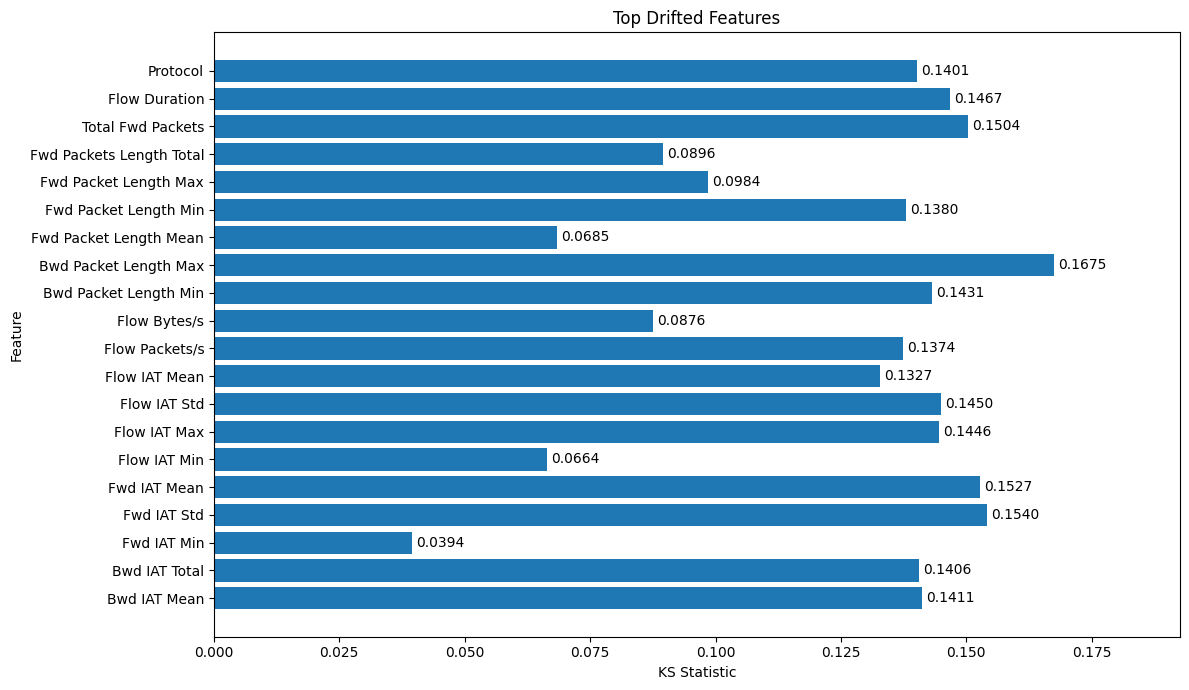

In [18]:
plt.figure(figsize=(12, 7))

# 1. Gán biểu đồ barh vào biến 'bars'
bars = plt.barh(
    top_drift["Feature"][::-1],
    top_drift["KS_Statistic"][::-1]
)

# 2. Hiển thị số chi tiết ở đầu mỗi thanh bar (lấy 4 chữ số thập phân)
plt.bar_label(bars, fmt='%.4f', padding=3)

# 3. Mở rộng trục X một chút để số không bị đè/mất viền
plt.xlim(0, top_drift["KS_Statistic"].max() * 1.15)

plt.xlabel("KS Statistic")
plt.ylabel("Feature")
plt.title("Top Drifted Features")

plt.tight_layout()
plt.show()

# Save drift

In [19]:
drift_df.to_csv(
    "../Results/drift_results.csv",
    index=False
)

print("Drift results saved.")

Drift results saved.
